# Multi-Class Sentiment Analysis — 4 Model Case Study

**Models:** Simple RNN, LSTM, GRU, DistilBERT (pre-trained Transformer)
**Dataset:** `sentiment_data.csv` (~241K comments)
**Classes:** 0 = Negative, 1 = Neutral, 2 = Positive

**How to run in Colab:** Runtime → Change runtime type → **GPU (T4)**, upload `sentiment_data.csv` to `/content/`, then Runtime → **Run all**.

In [ ]:
# Run once in Google Colab. (TensorFlow is already installed in Colab; we do NOT upgrade it,
# which avoids the dependency-conflict errors.)
!pip -q install transformers accelerate

In [ ]:
import os, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load the dataset

In [ ]:
DATA_PATH = "/content/sentiment_data.csv"

# If the file is not found, ask for an upload (Colab only)
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print("Please upload sentiment_data.csv")
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        DATA_PATH = "sentiment_data.csv"   # local run

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isna().sum())
display(df.head())

Shape: (241145, 3)

Columns: ['Unnamed: 0', 'Comment', 'Sentiment']

Missing values:
Unnamed: 0      0
Comment       217
Sentiment       0
dtype: int64


,Unnamed: 0,Comment,Sentiment
0,0,lets forget apple pay required brand new iphon...,1
1,1,nz retailers don’t even contactless credit car...,0
2,2,forever acknowledge channel help lessons ideas...,2
3,3,whenever go place doesn’t take apple pay doesn...,0
4,4,apple pay convenient secure easy use used kore...,2


## 2. Data cleaning

In [ ]:
df = df[["Comment", "Sentiment"]].copy()

# Remove rows with missing values
df = df.dropna(subset=["Comment", "Sentiment"])

# Remove duplicate comments (done BEFORE splitting to prevent train/test leakage)
df = df.drop_duplicates(subset=["Comment"]).reset_index(drop=True)

df["Comment"] = df["Comment"].astype(str).str.strip()
df["Sentiment"] = df["Sentiment"].astype(int)

# Keep only the three expected labels
df = df[df["Sentiment"].isin([0, 1, 2])].reset_index(drop=True)

label_names = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Cleaned shape:", df.shape)
print("\nClass distribution:")
print(df["Sentiment"].value_counts().sort_index())

display(df["Sentiment"].value_counts().sort_index().rename(index=label_names).to_frame("count"))

Cleaned shape: (214157, 2)

Class distribution:
Sentiment
0    48269
1    71692
2    94196
Name: count, dtype: int64


,count
Sentiment,
Negative,48269
Neutral,71692
Positive,94196


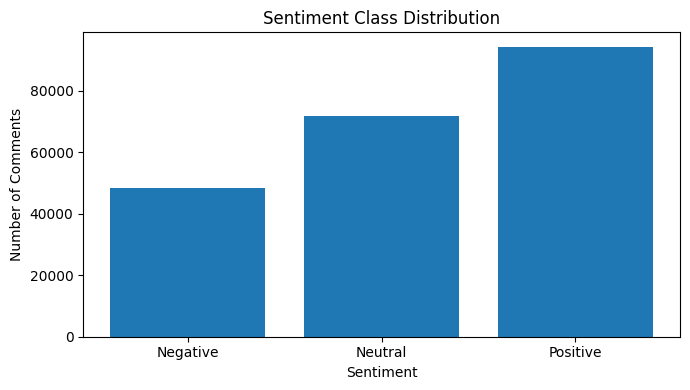

In [ ]:
counts = df["Sentiment"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar([label_names[i] for i in counts.index], counts.values)
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

## 3. Train / validation / test split (80 / 10 / 10, stratified)

In [ ]:
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["Sentiment"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["Sentiment"], random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{name} distribution:")
    print(d["Sentiment"].value_counts(normalize=True).sort_index())

Train: 171325
Validation: 21416
Test: 21416

Train distribution:
Sentiment
0    0.225390
1    0.334761
2    0.439848
Name: proportion, dtype: float64

Validation distribution:
Sentiment
0    0.225392
1    0.334750
2    0.439858
Name: proportion, dtype: float64

Test distribution:
Sentiment
0    0.225392
1    0.334796
2    0.439811
Name: proportion, dtype: float64


## 4. Text preprocessing and tokenization (for RNN / LSTM / GRU)

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_texts = train_df["Comment"].map(clean_text).tolist()
val_texts   = val_df["Comment"].map(clean_text).tolist()
test_texts  = test_df["Comment"].map(clean_text).tolist()

y_train = train_df["Sentiment"].to_numpy()
y_val   = val_df["Sentiment"].to_numpy()
y_test  = test_df["Sentiment"].to_numpy()

print(train_texts[:2])

['still playing wii fit lol fun fun fun movies tonight ill upload photos took today right check next tweet', 'feel trio modi mamta raga maza aajayega debate every election like usa presidential candidates debate moderated anchors every channel']


In [ ]:
VOCAB_SIZE = 20000
MAX_LEN = 128
EMBED_DIM = 128

tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")

# Fit only on training text to avoid vocabulary leakage
tokenizer.fit_on_texts(train_texts)

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return tf.keras.preprocessing.sequence.pad_sequences(
        seqs, maxlen=MAX_LEN, padding="post", truncating="post"
    )

X_train = to_padded(train_texts)
X_val   = to_padded(val_texts)
X_test  = to_padded(test_texts)

actual_vocab_size = min(VOCAB_SIZE, len(tokenizer.word_index) + 1)

print("Vocabulary used:", actual_vocab_size)
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Vocabulary used: 20000
Train shape: (171325, 128)
Validation shape: (21416, 128)
Test shape: (21416, 128)


## 5. Common settings, callbacks and evaluation utility

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6
)

BATCH_SIZE = 128
EPOCHS = 5
NUM_CLASSES = 3

results = []
trained_models = {}
histories = {}

def evaluate_keras_model(model, model_name, history, X_test, y_test, training_time):
    start = time.perf_counter()
    probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    inference_time = time.perf_counter() - start
    preds = np.argmax(probs, axis=1)

    acc = accuracy_score(y_test, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, preds, average="weighted", zero_division=0
    )
    macro_f1 = precision_recall_fscore_support(
        y_test, preds, average="macro", zero_division=0
    )[2]

    epochs_run = len(history.history["loss"])

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Macro F1": macro_f1,
        "Epochs Run": epochs_run,
        "Training Time (s)": training_time,
        "Time / Epoch (s)": training_time / epochs_run,
        "Inference Time (s)": inference_time,
        "Parameters": model.count_params()
    })
    trained_models[model_name] = model
    histories[model_name] = history.history

    print(f"\n{model_name}  (epochs run: {epochs_run})")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}   |   Macro F1: {macro_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(
        y_test, preds,
        target_names=[label_names[i] for i in range(NUM_CLASSES)],
        digits=4, zero_division=0
    ))
    return preds, probs

def build_recurrent(layer_cls, units=64):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN,)),
        tf.keras.layers.Embedding(input_dim=actual_vocab_size, output_dim=EMBED_DIM, mask_zero=True),
        layer_cls(units),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

## 6. Model 1 — Simple RNN
Architecture: Embedding → SimpleRNN → Dropout → Dense → Softmax

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

rnn = build_recurrent(tf.keras.layers.SimpleRNN)
rnn.summary()

start = time.perf_counter()
history_rnn = rnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr], verbose=1
)
rnn_training_time = time.perf_counter() - start

rnn_preds, rnn_probs = evaluate_keras_model(
    rnn, "Simple RNN", history_rnn, X_test, y_test, rnn_training_time
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 128, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,572,547 (9.81 MB)

 Trainable params: 2,572,547 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.7521 - loss: 0.6603 - val_accuracy: 0.8151 - val_loss: 0.5409 - learning_rate: 0.0010
Epoch 2/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.8364 - loss: 0.4725 - val_accuracy: 0.8169 - val_loss: 0.5216 - learning_rate: 0.0010
Epoch 3/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.8789 - loss: 0.3482 - val_accuracy: 0.8082 - val_loss: 0.5745 - learning_rate: 0.0010
Epoch 4/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.9296 - loss: 0.2125 - val_accuracy: 0.7975 - val_loss: 0.7051 - learning_rate: 5.0000e-04

Simple RNN  (epochs run: 4)
Accuracy : 0.8119
Precision: 0.8110
Recall   : 0.8119
F1-score : 0.8102   |   Macro F1: 0.7971

Classification Report:
              precision    recall  f1-score   support

    Negative     0.7847    0.6735    0.7249      4827
     Neutral     0.7962    0.8448    0.8198      7170
    Positive     0.8358    0.8577    0.8466      9419

    accura

## 7. Model 2 — LSTM
Architecture: Embedding → LSTM → Dropout → Dense → Softmax

In [ ]:
tf.random.set_seed(SEED)

lstm = build_recurrent(tf.keras.layers.LSTM)
lstm.summary()

start = time.perf_counter()
history_lstm = lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr], verbose=1
)
lstm_training_time = time.perf_counter() - start

lstm_preds, lstm_probs = evaluate_keras_model(
    lstm, "LSTM", history_lstm, X_test, y_test, lstm_training_time
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 128, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,609,603 (9.95 MB)

 Trainable params: 2,609,603 (9.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.7859 - loss: 0.5670 - val_accuracy: 0.8403 - val_loss: 0.4445 - learning_rate: 0.0010
Epoch 2/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.8539 - loss: 0.4002 - val_accuracy: 0.8413 - val_loss: 0.4393 - learning_rate: 0.0010
Epoch 3/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.8736 - loss: 0.3458 - val_accuracy: 0.8391 - val_loss: 0.4689 - learning_rate: 0.0010
Epoch 4/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.9007 - loss: 0.2733 - val_accuracy: 0.8303 - val_loss: 0.5445 - learning_rate: 5.0000e-04

LSTM  (epochs run: 4)
Accuracy : 0.8402
Precision: 0.8411
Recall   : 0.8402
F1-score : 0.8393   |   Macro F1: 0.8292

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8333    0.7282    0.7772      4827
     Neutral     0.8046    0.8764    0.8390      7170
    Positive     0.8728    0.8699    0.8714      9419

    accuracy    

## 8. Model 3 — GRU
Architecture: Embedding → GRU → Dropout → Dense → Softmax

In [ ]:
tf.random.set_seed(SEED)

gru = build_recurrent(tf.keras.layers.GRU)
gru.summary()

start = time.perf_counter()
history_gru = gru.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr], verbose=1
)
gru_training_time = time.perf_counter() - start

gru_preds, gru_probs = evaluate_keras_model(
    gru, "GRU", history_gru, X_test, y_test, gru_training_time
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 128, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,597,443 (9.91 MB)

 Trainable params: 2,597,443 (9.91 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7870 - loss: 0.5674 - val_accuracy: 0.8411 - val_loss: 0.4477 - learning_rate: 0.0010
Epoch 2/5
1339/1339 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8564 - loss: 0.3947 - val_accuracy: 0.8401 - val_loss: 0.4461 - learning_rate: 5.0000e-04

GRU  (epochs run: 2)
Accuracy : 0.8395
Precision: 0.8391
Recall   : 0.8395
F1-score : 0.8385   |   Macro F1: 0.8289

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8227    0.7354    0.7766      4827
     Neutral     0.8272    0.8612    0.8439      7170
    Positive     0.8565    0.8762    0.8662      9419

    accuracy                         0.8395     21416
   macro avg     0.8355    0.8243    0.8289     21416
weighted avg     0.8391    0.8395    0.8385     21416



## 9. Model 4 — Pre-trained Transformer: DistilBERT
Checkpoint: `distilbert-base-uncased`, fine-tuned for 3-class classification (PyTorch + Hugging Face).
Texts are tokenized once up front (faster than tokenizing every item inside the DataLoader).

In [ ]:
import os, re, time, random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report
)

SEED = 42
NUM_CLASSES = 3
label_names = {0: "Negative", 1: "Neutral", 2: "Positive"}
random.seed(SEED)
np.random.seed(SEED)

if "results" not in globals():
    results = []
if "trained_models" not in globals():
    trained_models = {}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

needed = ["train_texts", "val_texts", "test_texts", "y_train", "y_val", "y_test"]

if all(n in globals() for n in needed):
    print("Data already in memory - nothing to rebuild.")
else:
    print("Rebuilding data from CSV (same cleaning and same split as the notebook)...")
    df = pd.read_csv("/content/sentiment_data.csv")
    df = df[["Comment", "Sentiment"]].copy()
    df = df.dropna(subset=["Comment", "Sentiment"])
    df = df.drop_duplicates(subset=["Comment"]).reset_index(drop=True)
    df["Comment"] = df["Comment"].astype(str).str.strip()
    df["Sentiment"] = df["Sentiment"].astype(int)
    df = df[df["Sentiment"].isin([0, 1, 2])].reset_index(drop=True)

    train_df, temp_df = train_test_split(
        df, test_size=0.20, stratify=df["Sentiment"], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df["Sentiment"], random_state=SEED
    )

    train_texts = train_df["Comment"].map(clean_text).tolist()
    val_texts   = val_df["Comment"].map(clean_text).tolist()
    test_texts  = test_df["Comment"].map(clean_text).tolist()
    y_train = train_df["Sentiment"].to_numpy()
    y_val   = val_df["Sentiment"].to_numpy()
    y_test  = test_df["Sentiment"].to_numpy()

print("Train / Val / Test:", len(train_texts), len(val_texts), len(test_texts))

Rebuilding data from CSV (same cleaning and same split as the notebook)...
Train / Val / Test: 171325 21416 21416


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", device)

BERT_MODEL_NAME = "distilbert-base-uncased"
BERT_MAX_LEN = 128
BERT_BATCH_SIZE = 16
BERT_EPOCHS = 2
BERT_LR = 2e-5

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

PyTorch device: cuda


In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        enc = tokenizer(
            list(texts), truncation=True, padding="max_length",
            max_length=max_len, return_tensors="pt"
        )
        self.input_ids = enc["input_ids"]
        self.attention_mask = enc["attention_mask"]
        self.labels = torch.tensor(list(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "labels": self.labels[idx]
        }

bert_train_ds = SentimentDataset(train_texts, y_train, bert_tokenizer, BERT_MAX_LEN)
bert_val_ds   = SentimentDataset(val_texts,   y_val,   bert_tokenizer, BERT_MAX_LEN)
bert_test_ds  = SentimentDataset(test_texts,  y_test,  bert_tokenizer, BERT_MAX_LEN)

pin = torch.cuda.is_available()
bert_train_loader = DataLoader(bert_train_ds, batch_size=BERT_BATCH_SIZE, shuffle=True,  pin_memory=pin)
bert_val_loader   = DataLoader(bert_val_ds,   batch_size=BERT_BATCH_SIZE, shuffle=False, pin_memory=pin)
bert_test_loader  = DataLoader(bert_test_ds,  batch_size=BERT_BATCH_SIZE, shuffle=False, pin_memory=pin)

print(len(bert_train_ds), len(bert_val_ds), len(bert_test_ds))

171325 21416 21416


In [ ]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME, num_labels=NUM_CLASSES
)
bert_model.to(device)

optimizer = torch.optim.AdamW(bert_model.parameters(), lr=BERT_LR)

total_training_steps = len(bert_train_loader) * BERT_EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

def evaluate_bert(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return np.array(all_labels), np.array(all_preds)

print("Trainable parameters:", sum(p.numel() for p in bert_model.parameters() if p.requires_grad))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 66955779


In [ ]:
best_val_f1 = -1.0
best_state = None
bert_history = {"train_loss": [], "val_f1": []}

start = time.perf_counter()

for epoch in range(BERT_EPOCHS):
    bert_model.train()
    total_loss = 0.0

    for batch in bert_train_loader:
        optimizer.zero_grad(set_to_none=True)

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

    val_labels, val_preds = evaluate_bert(bert_model, bert_val_loader)
    val_f1 = precision_recall_fscore_support(
        val_labels, val_preds, average="weighted", zero_division=0
    )[2]
    avg_loss = total_loss / len(bert_train_loader)

    bert_history["train_loss"].append(avg_loss)
    bert_history["val_f1"].append(val_f1)
    print(f"Epoch {epoch+1}/{BERT_EPOCHS} | Train Loss: {avg_loss:.4f} | Val F1: {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {k: v.detach().cpu().clone() for k, v in bert_model.state_dict().items()}

bert_training_time = time.perf_counter() - start

# Restore best validation checkpoint
bert_model.load_state_dict(best_state)
bert_model.to(device)
print(f"\nDistilBERT training time: {bert_training_time:.1f} s")

Epoch 1/2 | Train Loss: 0.5068 | Val F1: 0.8616
Epoch 2/2 | Train Loss: 0.3432 | Val F1: 0.8722

DistilBERT training time: 4394.1 s


In [ ]:
start = time.perf_counter()
test_labels_bert, test_preds_bert = evaluate_bert(bert_model, bert_test_loader)
bert_inference_time = time.perf_counter() - start

bert_accuracy = accuracy_score(test_labels_bert, test_preds_bert)
bert_precision, bert_recall, bert_f1, _ = precision_recall_fscore_support(
    test_labels_bert, test_preds_bert, average="weighted", zero_division=0
)
bert_macro_f1 = precision_recall_fscore_support(
    test_labels_bert, test_preds_bert, average="macro", zero_division=0
)[2]
bert_parameters = sum(p.numel() for p in bert_model.parameters())

# Remove any earlier DistilBERT row so re-running never creates duplicates
results[:] = [r for r in results if r["Model"] != "DistilBERT"]

results.append({
    "Model": "DistilBERT",
    "Accuracy": bert_accuracy,
    "Precision": bert_precision,
    "Recall": bert_recall,
    "F1-Score": bert_f1,
    "Macro F1": bert_macro_f1,
    "Epochs Run": BERT_EPOCHS,
    "Training Time (s)": bert_training_time,
    "Time / Epoch (s)": bert_training_time / BERT_EPOCHS,
    "Inference Time (s)": bert_inference_time,
    "Parameters": bert_parameters
})
trained_models["DistilBERT"] = bert_model

print("DistilBERT Results")
print(f"Accuracy : {bert_accuracy:.4f}")
print(f"Precision: {bert_precision:.4f}")
print(f"Recall   : {bert_recall:.4f}")
print(f"F1-score : {bert_f1:.4f}   |   Macro F1: {bert_macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    test_labels_bert, test_preds_bert,
    target_names=[label_names[i] for i in range(NUM_CLASSES)],
    digits=4, zero_division=0
))

DistilBERT Results
Accuracy : 0.8721
Precision: 0.8729
Recall   : 0.8721
F1-score : 0.8722   |   Macro F1: 0.8647

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8414    0.8179    0.8295      4827
     Neutral     0.8435    0.8893    0.8658      7170
    Positive     0.9114    0.8868    0.8989      9419

    accuracy                         0.8721     21416
   macro avg     0.8654    0.8647    0.8647     21416
weighted avg     0.8729    0.8721    0.8722     21416



## 10. Final model comparison

In [ ]:
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results_df)

results_df.to_csv("model_comparison_results.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-Score,Macro F1,Epochs Run,Training Time (s),Time / Epoch (s),Inference Time (s),Parameters
0,LSTM,0.840166,0.841082,0.840166,0.839312,0.829196,4,69.221879,17.305470,0.982036,2609603
1,GRU,0.839466,0.839062,0.839466,0.838549,0.828911,2,27.898433,13.949217,0.912600,2597443
2,Simple RNN,0.811870,0.811045,0.811870,0.810199,0.797094,4,86.269924,21.567481,1.701942,2572547


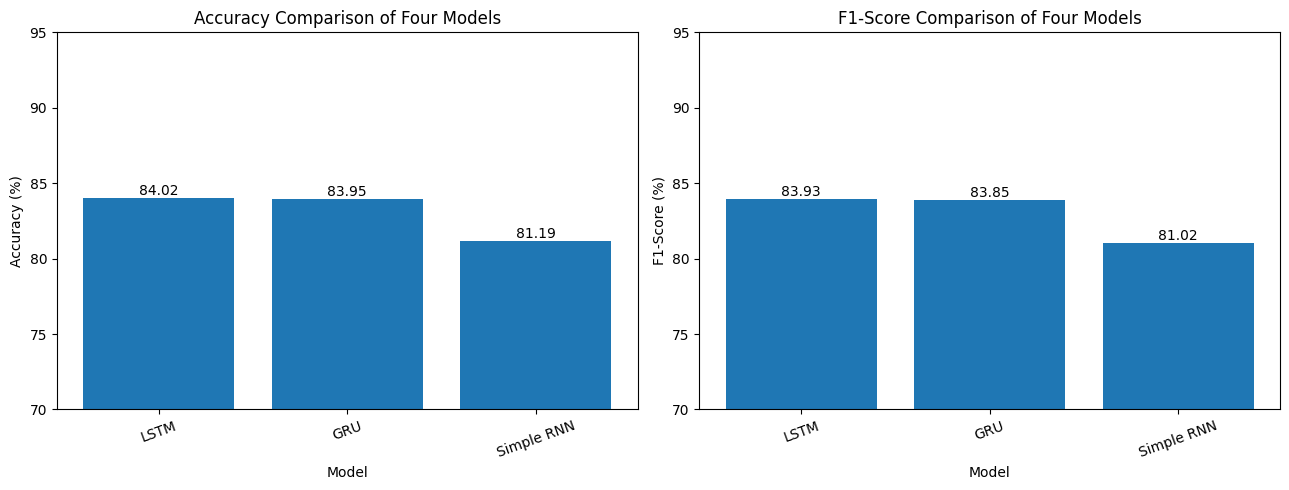

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric in zip(axes, ["Accuracy", "F1-Score"]):
    bars = ax.bar(results_df["Model"], results_df[metric] * 100)
    ax.set_ylim(70, 95)   # zoomed axis so the differences are visible
    ax.set_ylabel(f"{metric} (%)")
    ax.set_xlabel("Model")
    ax.set_title(f"{metric} Comparison of Four Models")
    ax.tick_params(axis="x", rotation=20)
    for b, v in zip(bars, results_df[metric] * 100):
        ax.text(b.get_x() + b.get_width()/2, v + 0.2, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
# Computational comparison
display(results_df[["Model", "Epochs Run", "Training Time (s)", "Time / Epoch (s)",
                    "Inference Time (s)", "Parameters"]])

,Model,Epochs Run,Training Time (s),Time / Epoch (s),Inference Time (s),Parameters
0,LSTM,4,69.221879,17.305470,0.982036,2609603
1,GRU,2,27.898433,13.949217,0.912600,2597443
2,Simple RNN,4,86.269924,21.567481,1.701942,2572547


In [ ]:
# Clean table for the presentation
presentation_table = results_df.copy()

for col in ["Accuracy", "Precision", "Recall", "F1-Score", "Macro F1"]:
    presentation_table[col] = (presentation_table[col] * 100).round(2).astype(str) + "%"

for col in ["Training Time (s)", "Time / Epoch (s)", "Inference Time (s)"]:
    presentation_table[col] = presentation_table[col].round(2)

display(presentation_table)

,Model,Accuracy,Precision,Recall,F1-Score,Macro F1,Epochs Run,Training Time (s),Time / Epoch (s),Inference Time (s),Parameters
0,LSTM,84.02%,84.11%,84.02%,83.93%,82.92%,4,69.22,17.31,0.98,2609603
1,GRU,83.95%,83.91%,83.95%,83.85%,82.89%,2,27.90,13.95,0.91,2597443
2,Simple RNN,81.19%,81.1%,81.19%,81.02%,79.71%,4,86.27,21.57,1.70,2572547


## 11. Training curves (RNN / LSTM / GRU)

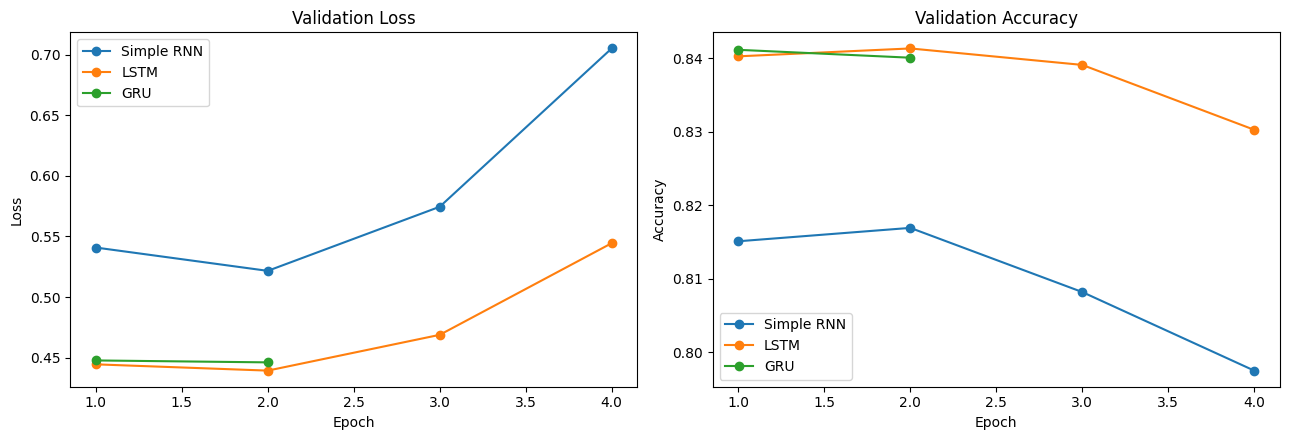

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, h in histories.items():
    axes[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", label=name)
    axes[1].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], marker="o", label=name)

axes[0].set_title("Validation Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].set_title("Validation Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Confusion matrices

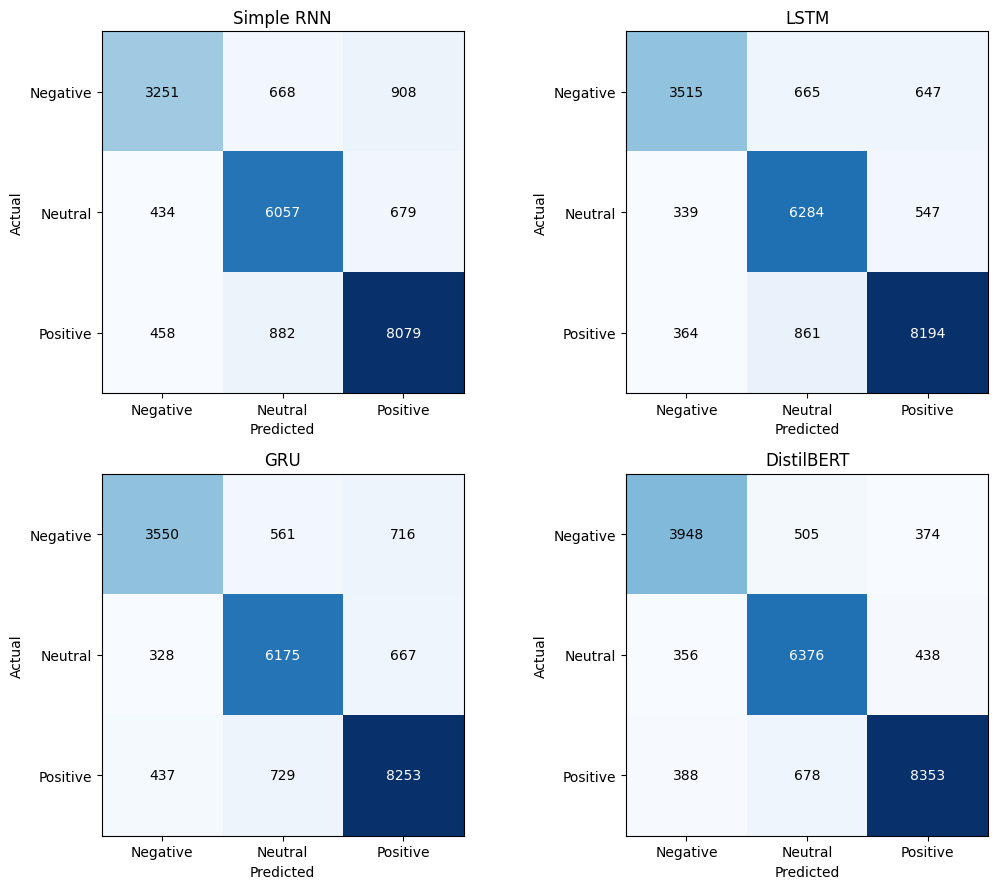

In [ ]:
prediction_dict = {
    "Simple RNN": rnn_preds,
    "LSTM": lstm_preds,
    "GRU": gru_preds,
    "DistilBERT": test_preds_bert
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()
tick_labels = ["Negative", "Neutral", "Positive"]

for ax, (name, preds) in zip(axes, prediction_dict.items()):
    cm = confusion_matrix(y_test, preds, labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1, 2]); ax.set_yticks([0, 1, 2])
    ax.set_xticklabels(tick_labels); ax.set_yticklabels(tick_labels)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

## 13. Sample predictions
The same Keras tokenizer is used for RNN / LSTM / GRU; DistilBERT uses its own pretrained tokenizer.

In [ ]:
def predict_custom(model, text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    seq = tf.keras.preprocessing.sequence.pad_sequences(
        seq, maxlen=MAX_LEN, padding="post", truncating="post"
    )
    probs = model.predict(seq, verbose=0)[0]
    pred = int(np.argmax(probs))
    return label_names[pred], float(probs[pred])

def predict_distilbert(text):
    bert_model.eval()
    encoding = bert_tokenizer(
        text, truncation=True, padding="max_length",
        max_length=BERT_MAX_LEN, return_tensors="pt"
    )
    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    with torch.no_grad():
        outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask)

    probs = torch.softmax(outputs.logits, dim=1)[0]
    pred = int(torch.argmax(probs).item())
    return label_names[pred], float(probs[pred].item())

In [ ]:
sample_comments = [
    "The product was excellent and I really enjoyed using it.",
    "It was okay, nothing particularly special.",
    "The experience was terrible and very disappointing."
]

for comment in sample_comments:
    print("\nComment:", comment)

    for name, model in [("Simple RNN", rnn), ("LSTM", lstm), ("GRU", gru)]:
        sentiment, confidence = predict_custom(model, comment)
        print(f"{name:20s}: {sentiment:8s} ({confidence*100:.2f}%)")

    sentiment, confidence = predict_distilbert(comment)
    print(f"{'DistilBERT':20s}: {sentiment:8s} ({confidence*100:.2f}%)")


Comment: The product was excellent and I really enjoyed using it.
Simple RNN          : Positive (96.33%)
LSTM                : Positive (98.07%)
GRU                 : Positive (92.23%)
DistilBERT          : Positive (99.53%)

Comment: It was okay, nothing particularly special.
Simple RNN          : Positive (92.93%)
LSTM                : Positive (49.36%)
GRU                 : Positive (68.44%)
DistilBERT          : Neutral  (49.90%)

Comment: The experience was terrible and very disappointing.
Simple RNN          : Negative (98.33%)
LSTM                : Negative (97.65%)
GRU                 : Negative (95.96%)
DistilBERT          : Negative (98.40%)


## 14. Error analysis — misclassified test comments (DistilBERT)

In [ ]:
test_eval_df = test_df.reset_index(drop=True).copy()
test_eval_df["Predicted"] = test_preds_bert
wrong = test_eval_df[test_eval_df["Sentiment"] != test_eval_df["Predicted"]].copy()
wrong["Actual"] = wrong["Sentiment"].map(label_names)
wrong["Predicted"] = wrong["Predicted"].map(label_names)

print(f"Misclassified: {len(wrong)} of {len(test_eval_df)} ({len(wrong)/len(test_eval_df)*100:.2f}%)")
pd.set_option("display.max_colwidth", 140)
display(wrong[["Comment", "Actual", "Predicted"]].sample(10, random_state=SEED))

## 15. Save the trained models
Run this after all four models have trained successfully.

In [ ]:
os.makedirs("saved_models", exist_ok=True)

rnn.save("saved_models/simple_rnn.keras")
lstm.save("saved_models/lstm.keras")
gru.save("saved_models/gru.keras")

bert_model.save_pretrained("saved_models/distilbert_sentiment")
bert_tokenizer.save_pretrained("saved_models/distilbert_sentiment")

print("All four models saved.")